# 2.1 Simple linear regression

One predictor (`monthly_usage`), one target (`monthly_spend`). Least
squares, residual plots, R² / standard error, and a small forecast --
the small end-to-end example the slides build up slide by slide.

## Setup

Throughout this notebook (and every other notebook in this folder) we reuse
the **same 300-row synthetic customer table** (`data/customers.csv`, see
`data/generate_customers.py`): a small telecom/subscription dataset with a
continuous target (`monthly_spend`) for regression notebooks and a binary
target (`churned`) for classification notebooks, plus a block of numeric
features used for resampling, evaluation-metric, dimensionality-reduction
and clustering demos. The point isn't the dataset -- it's small and
synthetic on purpose -- the point is seeing each technique applied to
something you already recognise from the last notebook.

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath("common"))
sys.path.insert(0, os.path.abspath("../common"))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

CUSTOMERS_PATH = "data/customers.csv" if os.path.exists("data/customers.csv") else "../data/customers.csv"
df = pd.read_csv(CUSTOMERS_PATH)
df.head()

,customer_id,age,region,tenure_months,income_k,monthly_usage,support_calls,discount_pct,satisfaction,monthly_spend,churned
0,C0001,45.7,South,90.7,78.1,8.3,2,0,8.12,39.35,0
1,C0002,29.5,North,54.9,58.4,27.3,6,5,5.80,51.69,0
2,C0003,51.0,West,28.6,73.3,13.9,5,0,5.48,37.75,1
3,C0004,53.3,West,22.9,106.5,13.3,6,10,9.25,34.31,1
4,C0005,18.6,West,45.7,35.5,67.2,6,15,7.26,52.28,0


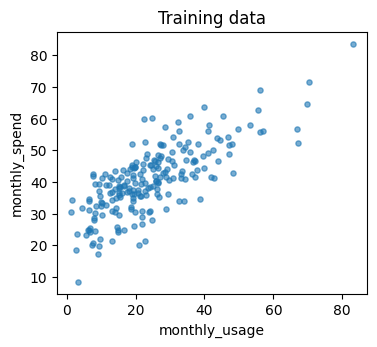

In [2]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error

Xtr, Xte, ytr, yte = train_test_split(df[["monthly_usage"]], df["monthly_spend"], test_size=0.3, random_state=0)

fig, ax = plt.subplots(figsize=(4, 3.4))
ax.scatter(Xtr, ytr, s=14, alpha=0.6)
ax.set_xlabel("monthly_usage"); ax.set_ylabel("monthly_spend"); ax.set_title("Training data")
plt.show()

## Model estimation: least squares

In [3]:
model = LinearRegression().fit(Xtr, ytr)
print(f"Fitted line: monthly_spend = {model.intercept_:.2f} + {model.coef_[0]:.2f} * monthly_usage")

Fitted line: monthly_spend = 26.38 + 0.59 * monthly_usage


## Interpretation, goodness-of-fit and standard error

In [4]:
pred_test = model.predict(Xte)
r2 = r2_score(yte, pred_test)
resid = yte - pred_test
se = (resid ** 2).sum() ** 0.5 / (len(yte) - 2) ** 0.5

print(f"R^2 (test)              = {r2:.3f}   -- share of variance in spend explained by usage alone")
print(f"Standard error of resid.= {se:.2f}   -- typical size of a leftover prediction error, in euros")
print(f"Interpretation: each extra unit of monthly_usage is associated with "
      f"{model.coef_[0]:.2f} euros more monthly spend, holding nothing else constant "
      f"(it's the only predictor here).")

R^2 (test)              = 0.519   -- share of variance in spend explained by usage alone
Standard error of resid.= 6.57   -- typical size of a leftover prediction error, in euros
Interpretation: each extra unit of monthly_usage is associated with 0.59 euros more monthly spend, holding nothing else constant (it's the only predictor here).


## Residual plots: what to look for

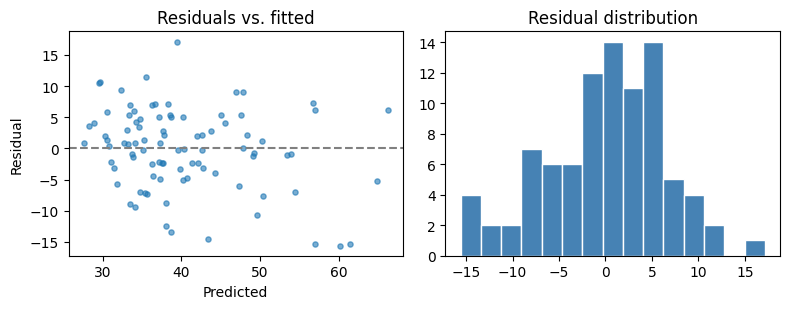

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(8, 3.2))
axes[0].scatter(pred_test, resid, s=14, alpha=0.6)
axes[0].axhline(0, color="grey", linestyle="--")
axes[0].set_xlabel("Predicted"); axes[0].set_ylabel("Residual"); axes[0].set_title("Residuals vs. fitted")

axes[1].hist(resid, bins=15, color="steelblue", edgecolor="white")
axes[1].set_title("Residual distribution")
plt.tight_layout(); plt.show()

No obvious funnel shape or curve in the residuals-vs-fitted plot means the
constant-variance / linearity assumptions aren't obviously violated here --
that's the visual check the "residual plots: what to look for" slide asks
you to run before trusting the R²/standard-error numbers above.

## Outliers and influential points

In [6]:
std_resid = (resid - resid.mean()) / resid.std()
outliers = Xte.assign(monthly_spend=yte, residual=resid, std_resid=std_resid)
outliers = outliers.reindex(std_resid.abs().sort_values(ascending=False).index).head(5)
outliers

,monthly_usage,monthly_spend,residual,std_resid
284,22.3,56.60,17.151652,2.640755
259,57.6,44.55,-15.581408,-2.372513
285,52.3,41.65,-15.376020,-2.341057
45,59.7,46.07,-15.291845,-2.328165
223,29.1,28.91,-14.522620,-2.210353


## A small forecast

In [7]:
new_customers = pd.DataFrame({"monthly_usage": [10, 40, 90]})
forecast = model.predict(new_customers)
new_customers.assign(predicted_spend=forecast.round(2))

,monthly_usage,predicted_spend
0,10,32.24
1,40,49.82
2,90,79.12


**Takeaway**: simple linear regression already gives an interpretable,
checkable model with one predictor -- Section 2.2 adds more predictors and
the extra bookkeeping (selection, multicollinearity) that come with them.